# 🔗 링크 예측 예제 — 트러스의 누락 부재 찾기

**건설빅데이터분석 · 그래프 신경망 · W09 링크 예측 · 예제 노트북 (실행 결과 포함)**

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/baekja/Lecture_GNN-AE-Practice/blob/main/PyG_LinkPred_Truss/truss_linkpred_example.ipynb)

> 도면을 디지털로 옮기거나 스캔 데이터로 구조 모델을 만들다 보면 **부재가 빠지는** 일이 생깁니다.
> 트러스를 그래프(절점 = 노드, 부재 = 엣지)로 보면 "빠진 부재 찾기"는 곧 **링크 예측**입니다.
> 이 노트북은 Pratt · Howe 트러스 60동을 직접 만들어, 강의노트의 휴리스틱 · GAE · 평가 방법을 그대로 적용하고,
> 마지막에 **직접강성법 구조해석**으로 복원한 트러스를 검증합니다.

| 절 | 내용 | 강의노트 |
|:-:|---|:-:|
| 1–2 | 트러스 생성 · 그래프 변환 · Maxwell 정정 조건 | 1절 |
| 3 | 문제 세우기 — 시험 트러스에서 부재 20% 가리기 | 1 · 7.4절 |
| 4 | 기준선 — 공통 이웃 · Adamic–Adar · 거리 · 차수 결손 | 2절 |
| 5 | GAE — 완전한 트러스에서 부재를 가려 가며 학습 (귀납) | 4 · 7.4절 |
| 6 | 채점 두 가지 — 무작위 음성 · 대각재 방향(어려운 음성) | 7절 |
| 7 | 구조 검증 — 예측으로 복원한 트러스를 직접강성법으로 해석 | — |
| 8 | 고쳐 보기 — MLP 디코더 + 어려운 음성 | 4.3 · 7.5절 |
| 9 | 시드 3개로 다시 | 7.5절 |

**사용법** — Colab에서 **파일 → Drive에 사본 저장** 후 위에서부터 차례대로 실행(`Shift + Enter`). GPU는 필요 없습니다(CPU 런타임 그대로).

## 0. 준비 — PyG 설치와 라이브러리
PyG가 없으면 설치하고(Colab), 오늘 쓸 도구를 불러옵니다.

In [1]:
import importlib.util, subprocess
if importlib.util.find_spec("torch_geometric") is None:           # Colab 처음 실행이면 PyG 설치
    subprocess.run(["pip", "install", "-q", "torch_geometric"], check=True)

import time, math, warnings
warnings.filterwarnings("ignore")                                   # 선택 확장 모듈 안내 등 경고 숨김
import numpy as np, pandas as pd, networkx as nx, matplotlib.pyplot as plt
import torch, torch_geometric as pyg
from torch import nn
from torch_geometric.nn import GAE, GCN                             # 강의노트 9.1절과 같은 GAE
from torch_geometric.utils import to_undirected, degree
print("torch", torch.__version__, "| PyG", pyg.__version__)
T0 = time.time()                                                    # ⏱ 노트북 전체 시간

torch 2.9.1 | PyG 2.7.0


## 1. 트러스 만들기 — Pratt와 Howe
평행현 트러스: 아래현 절점 `0..n`, 위현 절점 `n+1..2n+1`. 부재 = 아래현 n + 위현 n + 수직재 n+1 + **대각재 n**.
- **Pratt**: 대각재가 경간 중앙 쪽으로 **내려간다**(중력 하중에서 인장)
- **Howe**: 대각재가 경간 중앙 쪽으로 **올라간다**(압축)
- 두 형식은 **대각재 방향만** 다르다 → 한 패널에서 "어느 대각선이 부재인가"는 거리만으로는 알 수 없다(6절)

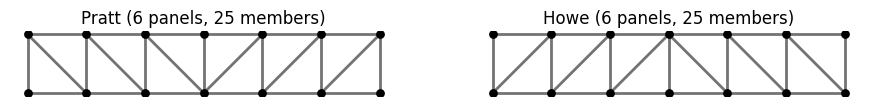

In [2]:
def make_truss(kind, n, w, h):
    """평행현 트러스. 반환: 절점 좌표(m), 부재 목록, 대각재 목록, 같은 패널의 '반대 대각선' 목록"""
    pos = np.array([(i * w, 0.0) for i in range(n + 1)] + [(i * w, h) for i in range(n + 1)])
    b, t = (lambda i: i), (lambda i: n + 1 + i)                     # 아래 · 위 절점 번호
    members = ([(b(i), b(i + 1)) for i in range(n)] + [(t(i), t(i + 1)) for i in range(n)]
               + [(b(i), t(i)) for i in range(n + 1)])               # 아래현 · 위현 · 수직재
    diag, other = [], []
    for i in range(n):                                               # 패널 i
        left = (i + 0.5) < n / 2                                     # 경간 중앙보다 왼쪽 패널인가
        down = (t(i), b(i + 1)) if left else (b(i), t(i + 1))        # 중앙 쪽으로 내려가는 대각선
        up = (b(i), t(i + 1)) if left else (t(i), b(i + 1))          # 중앙 쪽으로 올라가는 대각선
        d, o = (down, up) if kind == "Pratt" else (up, down)
        diag.append(d); other.append(o)
    return pos, members + diag, diag, other

def draw(ax, pos, members, title, **kw):
    for u, v in members:
        ax.plot(*zip(pos[u], pos[v]), color=kw.get("color", "0.45"), lw=kw.get("lw", 2), ls=kw.get("ls", "-"))
    ax.scatter(*pos.T, s=28, color="k", zorder=3); ax.set_title(title); ax.set_aspect("equal"); ax.axis("off")

fig, axs = plt.subplots(1, 2, figsize=(11, 2.6))
for ax, kind in zip(axs, ["Pratt", "Howe"]):
    pos, mem, diag, _ = make_truss(kind, 6, 2.0, 2.0)
    draw(ax, pos, mem, f"{kind} (6 panels, {len(mem)} members)")      # 그림 글자는 영어(Colab 기본 글꼴)
plt.show()

## 2. 그래프로 — 절점 = 노드, 부재 = 엣지
- 무작위 트러스 60동: 형식 Pratt/Howe 번갈아, 패널 수 4–8, 패널 폭 1.5–3.0 m, 높이 1.5–3.0 m
- **학습 40동**(도면이 완전함) · **시험 20동**(부재 일부가 빠진 도면이라고 가정) — 처음 보는 트러스에 쓰는 **귀납** 설정
- 노드 피처: 정규화 좌표 $x/L$, $y/h$, 지점 여부(왼쪽 핀 · 오른쪽 롤러). 5절에서 '보이는 부재 수(차수)'를 더한다
- **Maxwell 정정 조건**: 평면 트러스가 정정이려면 $m + r = 2j$ ($m$ 부재 수, $r$ 반력 수 3, $j$ 절점 수). 여기서 만든 트러스는 모두 $m + r = 2j$ — **부재가 하나만 빠져도 불안정**해진다

In [3]:
def make_set(count, first_kind, rng):
    out = []
    for g in range(count):
        kind = ["Pratt", "Howe"][(g + first_kind) % 2]
        n = int(rng.integers(4, 9)); w = float(rng.uniform(1.5, 3.0)); h = float(rng.uniform(1.5, 3.0))
        pos, mem, diag, other = make_truss(kind, n, w, h)
        out.append(dict(kind=kind, n=n, w=w, h=h, pos=pos, mem=mem, diag=diag, other=other))
    return out

def union(trusses):
    """여러 트러스를 서로 연결되지 않은 큰 그래프 하나로 (노드 번호를 이어 붙임)"""
    X, P, B, E, D, O, NM, off = [], [], [], [], [], [], [], 0
    for g, tr in enumerate(trusses):
        pos, n = tr["pos"], tr["n"]
        sup = np.zeros(len(pos)); sup[[0, n]] = 1                     # 지점: 왼쪽 아래 핀 · 오른쪽 아래 롤러
        X.append(np.c_[pos[:, 0] / pos[:, 0].max(), pos[:, 1] / tr["h"], sup]); P.append(pos)
        B += [g] * len(pos)
        mem = {tuple(sorted(e)) for e in tr["mem"]}
        NM += [(u + off, v + off) for u in range(len(pos)) for v in range(u + 1, len(pos)) if (u, v) not in mem]
        E += [(u + off, v + off) for u, v in tr["mem"]]
        D += [(u + off, v + off) for u, v in tr["diag"]]; O += [(u + off, v + off) for u, v in tr["other"]]
        off += len(pos)
    return dict(x=torch.tensor(np.vstack(X), dtype=torch.float), pos=np.vstack(P), batch=np.array(B),
                edges=torch.tensor(E).t(), nonmem=torch.tensor(NM).t(), diag=D, other=O)

rng = np.random.default_rng(0); pyg.seed_everything(0)
train_set, test_set = make_set(40, 0, rng), make_set(20, 1, rng)
tr_g, te_g = union(train_set), union(test_set)
for name, s, g in (("학습", train_set, tr_g), ("시험", test_set, te_g)):
    ok = all(len(t["mem"]) + 3 == 2 * len(t["pos"]) for t in s)       # Maxwell: m + r = 2j
    print(f"{name} {len(s)}동 | 절점 {g['x'].size(0)} | 부재 {g['edges'].size(1)} | 모두 m + r = 2j: {ok}")

학습 40동 | 절점 600 | 부재 1080 | 모두 m + r = 2j: True
시험 20동 | 절점 268 | 부재 476 | 모두 m + r = 2j: True


## 3. 문제 세우기 — 시험 트러스에서 부재 20%를 가린다
- **가린 부재 = 양성**(맞혀야 할 정답) · **보이는 부재 = 메시지 엣지**(모델 입력) — 강의노트 7.4절
- **음성** = 같은 트러스 안에서 부재가 아닌 절점 쌍. 양성과 같은 수를 트러스마다 무작위로 뽑는다
- 몇 개가 빠졌는지는 Maxwell 식이 알려 준다: 빠진 수 $= 2j - r - m_{\text{보임}}$. **어느 것**이 빠졌는지가 링크 예측의 몫

시험: 보이는 부재 381 · 가린 부재(양성) 95 · 음성 95


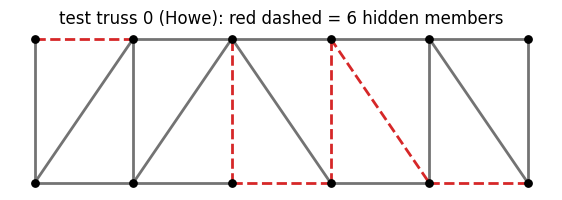

In [4]:
def hide(g, frac, rng):
    """부재의 frac을 가린다. 반환: 보이는 부재, 가린 부재(양성), 같은 수의 음성(트러스마다)"""
    E = g["edges"]; idx = rng.permutation(E.size(1)); k = int(frac * E.size(1))
    hidden, visible = E[:, idx[:k]], E[:, idx[k:]]
    gid = g["batch"][g["nonmem"][0].numpy()]
    neg = []
    for t, cnt in zip(*np.unique(g["batch"][hidden[0].numpy()], return_counts=True)):
        cand = np.where(gid == t)[0]
        neg += list(rng.choice(cand, size=cnt, replace=False))
    return visible, hidden, g["nonmem"][:, neg]

visible, hidden, neg = hide(te_g, 0.2, rng)
vis_ud = to_undirected(visible)
print(f"시험: 보이는 부재 {visible.size(1)} · 가린 부재(양성) {hidden.size(1)} · 음성 {neg.size(1)}")

t0 = test_set[0]; off0 = 0                                           # 첫 시험 트러스 그림
h0 = [tuple(e) for e in hidden.t().tolist() if e[0] < len(t0["pos"]) and e[1] < len(t0["pos"])]
v0 = [tuple(e) for e in visible.t().tolist() if e[0] < len(t0["pos"]) and e[1] < len(t0["pos"])]
fig, ax = plt.subplots(figsize=(7, 2.4))
draw(ax, t0["pos"], v0, f"test truss 0 ({t0['kind']}): red dashed = {len(h0)} hidden members")
for u, v in h0: ax.plot(*zip(t0["pos"][u], t0["pos"][v]), color="tab:red", lw=2, ls="--")
plt.show()

## 4. 기준선 — 학습 없이 세기 (강의노트 2절)
보이는 부재만으로 만든 그래프에서 점수를 매깁니다.
- **공통 이웃(CN)** · **Adamic–Adar(AA)**: 강의노트의 국소 휴리스틱
- **거리**: 가까운 절점일수록 높은 점수(부재는 이웃 절점끼리 잇는다는 기하 지식)
- **차수 결손**: 두 절점의 보이는 부재 수가 적을수록 높은 점수 — 부재가 빠진 절점은 연결이 모자라다(정정 트러스 지식)

채점은 **AUC**(양성–음성 대결 승률)와 **AP** — 강의노트 7절.

In [5]:
from sklearn.metrics import roc_auc_score, average_precision_score

def heuristic_scores(g, visible):
    G = nx.Graph(); G.add_nodes_from(range(g["x"].size(0))); G.add_edges_from(visible.t().tolist())
    pos = g["pos"]
    def score(pairs, kind):
        out = []
        for u, v in pairs.t().tolist():
            if kind == "공통 이웃": out.append(len(list(nx.common_neighbors(G, u, v))))
            elif kind == "Adamic–Adar": out.append(sum(1 / math.log(G.degree(c)) for c in nx.common_neighbors(G, u, v) if G.degree(c) > 1))
            elif kind == "거리": out.append(-float(np.hypot(*(pos[u] - pos[v]))))
            elif kind == "차수 결손": out.append(-(G.degree(u) + G.degree(v)))
        return np.array(out, dtype=float)
    return score

def auc_ap(sp, sn):
    y = np.r_[np.ones(len(sp)), np.zeros(len(sn))]; s = np.r_[sp, sn]
    return roc_auc_score(y, s), average_precision_score(y, s)

score_h = heuristic_scores(te_g, visible)
rows = {k: auc_ap(score_h(hidden, k), score_h(neg, k)) for k in ("공통 이웃", "Adamic–Adar", "거리", "차수 결손")}
pd.DataFrame(rows, index=["AUC", "AP"]).T.round(3)

,AUC,AP
공통 이웃,0.804,0.755
Adamic–Adar,0.804,0.754
거리,0.985,0.983
차수 결손,0.646,0.598


## 5. GAE — 완전한 트러스에서 부재를 가려 가며 배운다 (강의노트 4 · 7.4절)
- 모델은 강의노트 9.1절과 같은 **GAE**(2층 GCN 인코더 + 내적 디코더)
- 학습 트러스 40동은 도면이 완전하다 → 에폭마다 부재 20%를 무작위로 가려 **감독 엣지**로, 나머지를 **메시지 엣지**로 쓴다(`disjoint_train_ratio` 와 같은 생각)
- 음성 = 같은 트러스 안의 비부재 쌍(학습 트러스는 완전하므로 진짜 음성)
- 피처에 **보이는 부재 수(차수)/4** 를 더한다 — 메시지 엣지가 바뀔 때마다 다시 계산

In [6]:
def feats(g, msg_ud):
    return torch.cat([g["x"], (degree(msg_ud[0], g["x"].size(0)) / 4).view(-1, 1)], 1)

def train_gae(tr_g, epochs=300, mask=0.2, seed=0):
    pyg.seed_everything(seed)
    model = GAE(GCN(4, 64, num_layers=2, out_channels=32))         # 인코더 2층 GCN + 내적 디코더
    opt = torch.optim.Adam(model.parameters(), lr=0.01)
    E, NM = tr_g["edges"], tr_g["nonmem"]; losses = []
    for epoch in range(1, epochs + 1):
        model.train(); opt.zero_grad()
        m = torch.rand(E.size(1)) < mask                              # 이번 에폭에 가릴 부재
        sup, msg_ud = E[:, m], to_undirected(E[:, ~m])                # 감독 엣지 · 메시지 엣지
        z = model.encode(feats(tr_g, msg_ud), msg_ud)
        negs = NM[:, torch.randint(0, NM.size(1), (sup.size(1),))]    # 같은 수의 음성
        loss = model.recon_loss(z, sup, negs)                         # BCE (양성 평균 + 음성 평균)
        loss.backward(); opt.step(); losses.append(float(loss))
        if epoch % 100 == 0:                                          # 가리는 부재가 매번 달라 손실이 출렁인다 → 100에폭 평균
            print(f"epoch {epoch - 99:3d}–{epoch} | 평균 loss {np.mean(losses[-100:]):.3f}")
    return model

t = time.time()
model = train_gae(tr_g)
print(f"⏱ 학습 {time.time() - t:.1f}초")
model.eval()
with torch.no_grad():
    z = model.encode(feats(te_g, vis_ud), vis_ud)                     # 시험 트러스: 보이는 부재만 입력
gae = lambda pairs: (z[pairs[0]] * z[pairs[1]]).sum(1).numpy()        # 내적 점수(로짓)
rows["GAE"] = auc_ap(gae(hidden), gae(neg))
pd.DataFrame(rows, index=["AUC", "AP"]).T.round(3)

epoch   1–100 | 평균 loss 1.012
epoch 101–200 | 평균 loss 0.857
epoch 201–300 | 평균 loss 0.834
⏱ 학습 0.9초


,AUC,AP
공통 이웃,0.804,0.755
Adamic–Adar,0.804,0.754
거리,0.985,0.983
차수 결손,0.646,0.598
GAE,0.941,0.907


## 6. 채점 두 가지 — 쉬운 음성 대 어려운 음성 (강의노트 7.5절)
- 위 표의 음성은 **무작위** 비부재 쌍 → 대부분 멀리 떨어진 쌍이라 '거리' 하나로도 잘 가린다(쉬운 음성)
- **어려운 질문**: 대각재가 빠진 패널에서 **두 대각선 중 어느 것**이 부재였나? 두 대각선은 길이가 같고, 공통 이웃 수도 같다
- 채점: 숨긴 대각재와 같은 패널의 반대 대각선을 짝지어 대결 → 숨긴 대각재가 이긴 비율(비기면 ½)

In [7]:
def orientation_pairs(g, hidden):
    other = {tuple(sorted(d)): tuple(sorted(o)) for d, o in zip(g["diag"], g["other"])}
    hid = [tuple(sorted(e)) for e in hidden.t().tolist() if tuple(sorted(e)) in other]
    return torch.tensor(hid).t(), torch.tensor([other[e] for e in hid]).t()

def win_rate(sp, sn): return float(np.mean((sp > sn) + 0.5 * (sp == sn)))

dp, dn = orientation_pairs(te_g, hidden)
print("숨긴 대각재", dp.size(1), "개")
scorers = {k: (lambda p, k=k: score_h(p, k)) for k in ("공통 이웃", "Adamic–Adar", "거리", "차수 결손")}
scorers["GAE"] = gae
table = pd.DataFrame({k: [rows[k][0], rows[k][1], win_rate(f(dp), f(dn))] for k, f in scorers.items()},
                     index=["AUC (무작위 음성)", "AP (무작위 음성)", "대각재 방향 승률"]).T
table.round(3)

숨긴 대각재 20 개


,AUC (무작위 음성),AP (무작위 음성),대각재 방향 승률
공통 이웃,0.804,0.755,0.500
Adamic–Adar,0.804,0.754,0.450
거리,0.985,0.983,0.500
차수 결손,0.646,0.598,0.675
GAE,0.941,0.907,0.650


**읽는 법**
- 무작위 음성에서는 **거리**가 가장 높다 → 높은 AUC가 곧 어려운 쌍도 잘 가린다는 뜻은 아니다
- 대각재 방향에서 거리 · 공통 이웃은 0.5(구별 못 함) — 직사각형 패널의 두 대각선은 길이도 공통 이웃 수도 같다(대칭 때문에 점수가 같아지는 문제, 강의노트 6.4절과 같은 종류)
- **Adamic–Adar는 0.5보다 낮다** — 반대 대각선의 공통 이웃이 바로 '부재가 빠져 차수가 줄어든' 두 절점이라 AA가 오히려 가산점을 준다
- 차수 결손과 GAE는 0.5보다 높다 — 빠진 부재의 양 끝 절점은 연결이 하나씩 모자라다는 구조 신호를 쓴다

## 7. 구조 검증 — 예측으로 복원한 트러스를 해석한다
1. 시험 트러스에서 **보이는 부재만** 남기면 $m + r < 2j$ → 강성행렬이 특이(불안정) → 해석 불가
2. 빠진 개수 $k = 2j - r - m_{\text{보임}}$ 만큼 부재를 추가한다. 후보는 **길이가 패널 대각선 이하인 절점 쌍**(그보다 긴 부재는 없다는 기하 조건), 그중 점수 상위 $k$ 개
3. **직접강성법**으로 처짐을 계산해 원래 트러스와 비교 (강재 $E$ = 200 GPa, 단면적 $A$ = 2000 mm², 아래현 내부 절점마다 10 kN)
4. 시험 트러스 20동 전체에 대해 **완전 복원**(빠진 부재를 모두 맞힘) · **안정**(강성행렬이 정칙)인 트러스 수를 센다

In [8]:
def solve_truss(pos, members, n, P=10e3, E=200e9, A=2e-3):
    """2D 트러스 직접강성법. 왼쪽 아래 핀 · 오른쪽 아래 롤러, 아래현 내부 절점마다 P(N) 하향.
    반환: (최대 처짐 mm, None) 또는 (None, 강성행렬 계수 부족 수)"""
    N = len(pos); K = np.zeros((2 * N, 2 * N))
    for u, v in members:
        d = pos[v] - pos[u]; L = np.hypot(*d); c, s = d / L
        T = np.array([-c, -s, c, s]); idx = [2 * u, 2 * u + 1, 2 * v, 2 * v + 1]
        K[np.ix_(idx, idx)] += E * A / L * np.outer(T, T)             # 부재 강성을 전체 강성행렬에 조립
    free = [i for i in range(2 * N) if i not in (0, 1, 2 * n + 1)]   # 핀(x, y) · 롤러(y) 고정
    Kff = K[np.ix_(free, free)]; deficit = len(free) - np.linalg.matrix_rank(Kff)
    if deficit > 0: return None, deficit                             # 불안정(기구)
    F = np.zeros(2 * N); F[[2 * i + 1 for i in range(1, n)]] = -P
    u = np.zeros(2 * N); u[free] = np.linalg.solve(Kff, F[free])
    return -u[1::2].min() * 1e3, None

def restore_all(g, tset, visible, hidden, scorer):
    """시험 트러스마다 빠진 개수 k 만큼, 길이 조건을 만족하는 후보 중 점수 상위 k 쌍을 추가하고 해석한다"""
    out = []
    for t_id, tr in enumerate(tset):
        off = int(np.where(g["batch"] == t_id)[0][0]); N = len(tr["pos"])
        loc = lambda E: {tuple(sorted((u - off, v - off))) for u, v in E.t().tolist() if off <= u < off + N}
        vis, hid = loc(visible), loc(hidden)
        k = 2 * N - 3 - len(vis)                                      # Maxwell: 빠진 부재 수
        if k == 0: continue                                           # 가린 부재가 없는 트러스는 건너뜀
        L = 1.05 * math.hypot(tr["w"], tr["h"])                       # 가장 긴 부재 = 패널 대각선
        cand = [(u, v) for u in range(N) for v in range(u + 1, N)
                if (u, v) not in vis and np.hypot(*(tr["pos"][u] - tr["pos"][v])) <= L]
        s = scorer(torch.tensor([[u + off for u, v in cand], [v + off for u, v in cand]]))
        top = {cand[i] for i in np.argsort(-s, kind="stable")[:k]}   # 점수 상위 k 쌍
        d0, _ = solve_truss(tr["pos"], tr["mem"], tr["n"])            # 원래 트러스 처짐
        d1, lack = solve_truss(tr["pos"], list(vis | top), tr["n"])   # 복원한 트러스 처짐
        out.append(dict(트러스=t_id, k=k, 맞힘=len(top & hid), 완전복원=top == hid, 안정=d1 is not None,
                        처짐_원래=round(d0, 3), 처짐_복원=None if d1 is None else round(d1, 3), vis=vis, hid=hid, top=top))
    return pd.DataFrame(out)

methods = {"GAE": gae, "거리": lambda p: score_h(p, "거리"), "차수 결손": lambda p: score_h(p, "차수 결손")}
rest = {name: restore_all(te_g, test_set, visible, hidden, f) for name, f in methods.items()}
pd.DataFrame({name: {"트러스 수": len(df), "완전 복원": int(df.완전복원.sum()), "안정": int(df.안정.sum()),
                     "맞힌 부재 비율": round(df.맞힘.sum() / df.k.sum(), 3)} for name, df in rest.items()}).T

,트러스 수,완전 복원,안정,맞힌 부재 비율
GAE,20.0,0.0,0.0,0.495
거리,20.0,8.0,9.0,0.863
차수 결손,20.0,2.0,3.0,0.621


**읽는 법** — GAE는 무작위 음성 AUC가 높았지만(6절), 가까운 후보 사이에서 고르게 하면 트러스를 거의 복원하지 못한다(위 표의 완전 복원 수). 이유 둘:
- 학습 음성이 대부분 **멀리 떨어진 쌍**(쉬운 음성)이라, 가까운 쌍끼리 가르는 법을 배우지 못했다(강의노트 7.5절)
- **내적 디코더**는 두 임베딩이 '같은 방향'인지만 본다. 격자처럼 이웃이 여러 방향으로 퍼진 트러스의 연결을 내적 하나로 담기 어렵다

## 8. 고쳐 보기 — MLP 디코더 + 어려운 음성 (강의노트 4.3 · 7.5절)
두 가지만 바꾼다. 인코더(2층 GCN)와 학습 방식(부재를 가려 가며 학습)은 그대로.
1. **디코더를 MLP로**: 두 절점의 임베딩과 **좌표 차** $(\Delta x, \Delta y)$ 를 받아 점수를 낸다(강의노트 4.3절 '디코더를 MLP로 대체'). 쌍은 (아래·왼쪽 → 위·오른쪽) 순서로 맞춰 방향이 일관되게
2. **어려운 음성 섞기**: 학습 음성의 절반을 '길이가 패널 대각선 이하인 비부재 쌍'(예: 반대 대각선)에서 뽑는다. 학습 트러스는 도면이 완전하므로 이 쌍들은 진짜 음성이다

In [9]:
class PairMLP(nn.Module):
    """링크 디코더 = 작은 MLP: [z(아래·왼쪽 절점), z(위·오른쪽 절점), 좌표 차] → 점수(로짓)"""
    def __init__(self, d):
        super().__init__(); self.mlp = nn.Sequential(nn.Linear(2 * d + 2, 64), nn.ReLU(), nn.Linear(64, 1))
    def forward(self, z, x, e):
        u, v = e
        swap = (x[u, 1] > x[v, 1]) | ((x[u, 1] == x[v, 1]) & (x[u, 0] > x[v, 0]))   # 쌍의 순서 통일
        a, b = torch.where(swap, v, u), torch.where(swap, u, v)
        return self.mlp(torch.cat([z[a], z[b], x[b, :2] - x[a, :2]], 1)).view(-1)

def near_nonmembers(g, tset):
    """어려운 음성 후보: 같은 트러스 안에서 길이가 패널 대각선 이하인 비부재 쌍"""
    out = []
    for t_id, tr in enumerate(tset):
        off = int(np.where(g["batch"] == t_id)[0][0]); N = len(tr["pos"]); L = 1.05 * math.hypot(tr["w"], tr["h"])
        mem = {tuple(sorted(e)) for e in tr["mem"]}
        out += [(u + off, v + off) for u in range(N) for v in range(u + 1, N)
                if (u, v) not in mem and np.hypot(*(tr["pos"][u] - tr["pos"][v])) <= L]
    return torch.tensor(out).t()

def train_mlp(tr_g, tr_set, epochs=300, mask=0.2, seed=0):
    pyg.seed_everything(seed)
    enc, dec = GCN(4, 64, num_layers=2, out_channels=32), PairMLP(32)      # 인코더는 5절과 같은 2층 GCN
    opt = torch.optim.Adam(list(enc.parameters()) + list(dec.parameters()), lr=0.01)
    E, NM, X, HARD = tr_g["edges"], tr_g["nonmem"], tr_g["x"], near_nonmembers(tr_g, tr_set)
    for epoch in range(1, epochs + 1):
        opt.zero_grad()
        m = torch.rand(E.size(1)) < mask
        sup, msg_ud = E[:, m], to_undirected(E[:, ~m])                # 감독 엣지 · 메시지 엣지
        z = enc(feats(tr_g, msg_ud), msg_ud)
        h = int(0.5 * sup.size(1))                                    # 음성의 절반은 어려운(가까운) 쌍
        negs = torch.cat([NM[:, torch.randint(0, NM.size(1), (sup.size(1) - h,))],
                          HARD[:, torch.randint(0, HARD.size(1), (h,))]], 1)
        sp, sn = dec(z, X, sup), dec(z, X, negs)
        loss = nn.functional.binary_cross_entropy_with_logits(torch.cat([sp, sn]), torch.cat([torch.ones_like(sp), torch.zeros_like(sn)]))
        loss.backward(); opt.step()
    return enc, dec

t = time.time()
enc, dec = train_mlp(tr_g, train_set)
with torch.no_grad():
    z2 = enc(feats(te_g, vis_ud), vis_ud)
mlp = lambda p: dec(z2, te_g["x"], p).detach().numpy()
print(f"⏱ 학습 {time.time() - t:.1f}초")
rest["GNN + MLP 디코더"] = restore_all(te_g, test_set, visible, hidden, mlp)
scorers["GNN + MLP 디코더"] = mlp
cmp = {}
for name in ("거리", "차수 결손", "GAE", "GNN + MLP 디코더"):
    f, df = scorers[name], rest[name]
    cmp[name] = {"AUC (무작위 음성)": round(auc_ap(f(hidden), f(neg))[0], 3), "대각재 방향 승률": round(win_rate(f(dp), f(dn)), 3),
                 "완전 복원": f"{int(df.완전복원.sum())}/{len(df)}", "안정": f"{int(df.안정.sum())}/{len(df)}",
                 "맞힌 부재 비율": round(df.맞힘.sum() / df.k.sum(), 3)}
pd.DataFrame(cmp).T

⏱ 학습 1.0초


,AUC (무작위 음성),대각재 방향 승률,완전 복원,안정,맞힌 부재 비율
거리,0.985,0.5,8/20,9/20,0.863
차수 결손,0.646,0.675,2/20,3/20,0.621
GAE,0.941,0.65,0/20,0/20,0.495
GNN + MLP 디코더,0.995,0.65,8/20,10/20,0.832


시험 트러스 7 (Pratt, 패널 6) — 빠진 부재 k = 7개, 맞힌 부재 7개
  원래 트러스          : 최대 처짐 8.708 mm
  보이는 부재만        : 불안정 (강성행렬 계수가 7만큼 모자람)
  상위 k 로 복원한 트러스: 최대 처짐 8.708 mm


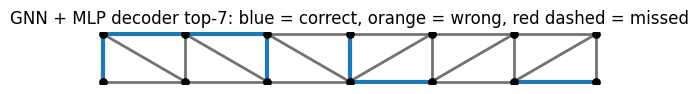

In [10]:
df = rest["GNN + MLP 디코더"]                                       # 복원 예: 완전 복원한 트러스 중 빠진 부재가 가장 많은 것
row = (df[df.완전복원] if df.완전복원.any() else df).sort_values("k", kind="stable").iloc[-1]
tr = test_set[int(row.트러스)]
d_vis, lack = solve_truss(tr["pos"], list(row.vis), tr["n"])
print(f"시험 트러스 {row.트러스} ({tr['kind']}, 패널 {tr['n']}) — 빠진 부재 k = {row.k}개, 맞힌 부재 {row.맞힘}개")
print(f"  원래 트러스          : 최대 처짐 {row.처짐_원래:.3f} mm")
print(f"  보이는 부재만        : 불안정 (강성행렬 계수가 {lack}만큼 모자람)")
print(f"  상위 k 로 복원한 트러스: " + (f"최대 처짐 {row.처짐_복원:.3f} mm" if row.안정 else "불안정"))
fig, ax = plt.subplots(figsize=(7, 2.6))
draw(ax, tr["pos"], list(row.vis), f"GNN + MLP decoder top-{row.k}: blue = correct, orange = wrong, red dashed = missed")
for u, v in row.top:
    ax.plot(*zip(tr["pos"][u], tr["pos"][v]), color="tab:blue" if (u, v) in row.hid else "tab:orange", lw=3)
for u, v in row.hid - row.top:
    ax.plot(*zip(tr["pos"][u], tr["pos"][v]), color="tab:red", lw=2, ls="--")
plt.show()

## 9. 시드 3개로 다시 — 한 번 실행한 숫자는 흔들린다 (강의노트 7.5절)
트러스 생성 · 가리기 · 학습을 시드 0, 1, 2로 반복해 평균 ± 표준편차를 봅니다.

In [11]:
import contextlib, io
t = time.time(); runs = []
for seed in (0, 1, 2):                                                # 시드마다 트러스 생성부터 다시
    r = np.random.default_rng(seed); pyg.seed_everything(seed)
    trs, tes = make_set(40, 0, r), make_set(20, 1, r)
    trg, teg = union(trs), union(tes)
    vis_s, hid_s, neg_s = hide(teg, 0.2, r); vud = to_undirected(vis_s)
    sh = heuristic_scores(teg, vis_s)
    with contextlib.redirect_stdout(io.StringIO()):                   # 학습 로그는 숨긴다
        m = train_gae(trg, seed=seed)
    m.eval()
    with torch.no_grad(): zz = m.encode(feats(teg, vud), vud)
    fs = {k: (lambda p, k=k: sh(p, k)) for k in ("공통 이웃", "Adamic–Adar", "거리", "차수 결손")}
    fs["GAE"] = lambda p: (zz[p[0]] * zz[p[1]]).sum(1).numpy()
    with contextlib.redirect_stdout(io.StringIO()):
        e2, d2 = train_mlp(trg, trs, seed=seed)
    with torch.no_grad(): zz2 = e2(feats(teg, vud), vud)
    fs["GNN + MLP 디코더"] = lambda p: d2(zz2, teg["x"], p).detach().numpy()
    dp_s, dn_s = orientation_pairs(teg, hid_s)
    for name, f in fs.items():
        rec = restore_all(teg, tes, vis_s, hid_s, f) if name in ("거리", "차수 결손", "GAE", "GNN + MLP 디코더") else None
        runs.append(dict(seed=seed, 방법=name, AUC=auc_ap(f(hid_s), f(neg_s))[0], 방향승률=win_rate(f(dp_s), f(dn_s)),
                         완전복원비율=np.nan if rec is None else rec.완전복원.mean()))
summary = pd.DataFrame(runs).groupby("방법", sort=False)[["AUC", "방향승률", "완전복원비율"]].agg(["mean", "std"]).round(3)
print(f"⏱ {time.time() - t:.1f}초")
summary

⏱ 6.8초


AUC          방향승률        완전복원비율       
                mean    std   mean    std   mean    std
방법                                                     
공통 이웃          0.768  0.034  0.493  0.012    NaN    NaN
Adamic–Adar    0.771  0.029  0.348  0.105    NaN    NaN
거리             0.986  0.001  0.500  0.000  0.267  0.126
차수 결손          0.683  0.033  0.769  0.085  0.050  0.050
GAE            0.922  0.023  0.761  0.099  0.000  0.000
GNN + MLP 디코더  0.992  0.005  0.802  0.131  0.467  0.115

In [12]:
print(f"⏱ 노트북 전체 {time.time() - T0:.0f}초")

⏱ 노트북 전체 10초


## 10. 정리
- 트러스 = 그래프(절점 · 부재) → **누락 부재 찾기 = 링크 예측**. 몇 개가 빠졌는지는 Maxwell 식($2j - r - m$), 어느 것인지는 모델의 몫
- **무작위 음성 AUC만 보면** 거리와 GAE가 모두 좋아 보인다(6절). 그러나 가까운 후보 중에서 고르는 실제 복원에서 GAE는 거의 쓸모가 없었다(7절) → 링크 예측 지표와 구조적 쓸모는 별개이고, **구조해석으로 검증**해야 한다
- 대칭인 두 대각선은 거리 · 공통 이웃으로 가를 수 없고, Adamic–Adar는 오히려 반대쪽을 고른다. '연결이 모자란 절점'이라는 구조 신호가 단서가 된다
- **디코더를 MLP로**(좌표 차 포함), **음성의 절반을 가까운 비부재로** 바꾸면 복원이 나아졌다(8 · 9절) — 음성을 어떻게 뽑고 디코더가 무엇을 보느냐가 모델이 배우는 것을 정한다
- 이 노트북의 숫자는 위 실행 결과(로컬 CPU, 각 셀의 출력)다. 다시 실행하면 환경에 따라 소수 셋째 자리가 달라질 수 있고, 시드 사이 표준편차도 크다(9절) — 결론은 여러 시드로 확인할 것

## ✏️ 직접 해 보기 (정답은 없습니다)
1. 8절의 두 변경(MLP 디코더 · 어려운 음성)을 **하나씩만** 켜 보라. 복원 성공에 어느 쪽이 더 크게 기여하는가?
2. 가리는 비율을 10% · 30%로 바꾸면 방법들의 순위가 바뀌는가?
3. 7–8절 표에서 '안정' 수가 '완전 복원' 수보다 많을 수 있다. 틀린 부재를 고르고도 안정한 트러스는 처짐이 원래와 얼마나 다른가? 왜 그런가?
4. 생성기에 Warren 트러스(수직재 없음)를 추가하면 Maxwell 조건과 결과는 어떻게 바뀌는가?